**LAPTOP PRICE PREDICTOR**

In this project, I predict the price of the laptop using its specifications like RAM,processor,screen,storage and brand.The data has 1303 rows and 13 columns. After cleaning i had 1231 laptops. I tried five models (Linear Regression, SVR, KNN, Decision Tree and Random Forest) and compared them using MAE, MSE, RMSE and R2. KNN and Random Forest gave the best results, with R2 of about 0.8.


**BUSINESS UNDERSTANDING**

Laptop prices depend on many things, so it is hard to know if a price is fair. 
The goal is to build a model that estimates the price from the specs. The target is Price and all the other columns are inputs. 
This is a regression problem because the price is a number.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

**PHASE 1 : DATA UNDERSTANDING**

In [2]:
import pandas as pd
df = pd.read_csv("laptop.csv", na_values=["?"])
df.shape

(1303, 13)

In [3]:
df.head()

,Unnamed: 0.1,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0.1      1303 non-null   int64  
 1   Unnamed: 0        1273 non-null   float64
 2   Company           1273 non-null   str    
 3   TypeName          1273 non-null   str    
 4   Inches            1272 non-null   float64
 5   ScreenResolution  1273 non-null   str    
 6   Cpu               1273 non-null   str    
 7   Ram               1273 non-null   str    
 8   Memory            1272 non-null   str    
 9   Gpu               1273 non-null   str    
 10  OpSys             1273 non-null   str    
 11  Weight            1272 non-null   str    
 12  Price             1273 non-null   float64
dtypes: float64(3), int64(1), str(9)
memory usage: 269.4 KB


The dataset has 1,303 rows and 13 columns. 30 rows are completely empty and three more have one missing value each (Inches, Memory, Weight). Ram and Weight are stored as text because of units (GB, kg), so I will convert them to numbers. The two Unnamed columns are only index numbers and carry no information, so I will remove them. Price has no missing values, which is good because it is what we want to predict.

In [5]:
df.describe() #number summary

,Unnamed: 0.1,Unnamed: 0,Inches,Price
count,1303.00000,1273.000000,1272.000000,1273.000000
mean,651.00000,652.674784,15.130818,59955.814073
std,376.28801,376.493027,1.954436,37332.251005
min,0.00000,0.000000,10.100000,9270.720000
25%,325.50000,327.000000,14.000000,31914.720000
50%,651.00000,652.000000,15.600000,52161.120000
75%,976.50000,980.000000,15.600000,79333.387200
max,1302.00000,1302.000000,35.600000,324954.720000


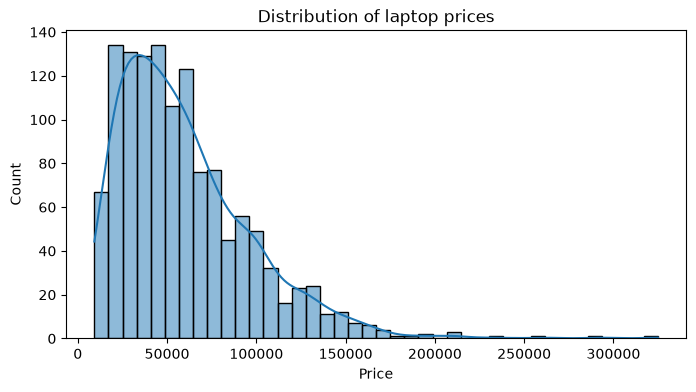

In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(df["Price"].dropna(), bins=40, kde=True)  #price histogram
plt.title("Distribution of laptop prices")
plt.xlabel("Price")
plt.show()    

The price distribution is right-skewed. Most laptops cost between about 20,000 and 65,000, while a small number of premium laptops (gaming and workstation models) cost over 150,000, with the highest near 325,000. Because the average is pulled up by these expensive laptops, the mean price is higher than the median. I expect the model to predict cheap and mid-range laptops more accurately than the very expensive ones, because there are far fewer examples of them. I will not delete these high prices, because they are real products.

In [7]:
df["Company"].value_counts()  #Count laptops per brand

Company
Lenovo       290
Dell         287
HP           266
Asus         156
Acer         103
MSI           53
Toshiba       47
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
LG             3
Huawei         2
Fujitsu        2
Name: count, dtype: int64

The dataset is dominated by Lenovo, Dell and HP, which make up about two thirds of all laptops. Many brands, such as Huawei, Fujitsu, Chuwi, Google and LG, have only 2 or 3 laptops. The model has very little to learn from for these brands, so its price predictions for them will be less reliable. Brand will still be useful as an input, since brand affects price.

**PHASE 2: DATA PREPROCESSING**



DATATYPES

In [8]:
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])

df["Inches"] = df["Inches"].astype(float)
df["Weight"] = df["Weight"].str.replace("kg", "", regex=False).astype(float)
df["Ram"] = df["Ram"].str.replace("GB", "", regex=False).astype(float)

df.dtypes

Company                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                 float64
Memory                  str
Gpu                     str
OpSys                   str
Weight              float64
Price               float64
dtype: object

Inches, Weight and Ram were stored as text because of units (kg, GB). I removed the units and converted them to numbers, so a model can do maths on them. I also dropped the two Unnamed columns because they were only old row numbers. ScreenResolution, Cpu, Memory and Gpu are still text with several facts packed in each, so I will split them in feature engineering.

Missing Values

In [9]:
df.isnull().sum()

Company             30
TypeName            30
Inches              31
ScreenResolution    30
Cpu                 30
Ram                 30
Memory              31
Gpu                 30
OpSys               30
Weight              31
Price               30
dtype: int64

In [10]:
df = df.dropna(how="all") #Remove empty rows
df.isnull().sum()

Company             0
TypeName            0
Inches              1
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              1
Gpu                 0
OpSys               0
Weight              1
Price               0
dtype: int64

30 rows were completely empty, so they held no laptop information and I removed them. 
After that, only 3 missing values remain: one each in Inches, Memory and Weight. 
This is a very small number, so I can remove those rows without losing much data.

In [11]:
df = df.dropna().reset_index(drop=True)
df["Ram"] = df["Ram"].astype(int)
df.shape

(1270, 11)

Duplicates

In [12]:
print(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df.shape

29


(1241, 11)

29 rows were duplicates, so I removed them. If the same laptop is in both the training set and the test set, the model can just remember it and the score will look better than it really is.

**PRICE OUTLIERS**

First the price, using the IQR rule.


In [13]:
Q1, Q3 = df["Price"].quantile([0.25, 0.75])
IQR = Q3 - Q1
price_outliers = df[(df["Price"] < Q1 - 1.5 * IQR) | (df["Price"] > Q3 + 1.5 * IQR)]
print(len(price_outliers))
price_outliers[["Company", "TypeName", "Ram", "Price"]].head()

28


,Company,TypeName,Ram,Price
17,Apple,Ultrabook,16,152274.24
189,Razer,Gaming,32,324954.72
197,Dell,Workstation,16,162770.40
229,Asus,Gaming,32,207259.20
238,Asus,Gaming,16,159786.72


28 laptops are flagged as price outliers. They are real, expensive gaming or workstation laptops, not mistakes. If I deleted them, the model could never learn to predict high prices, so I keep them.


weight

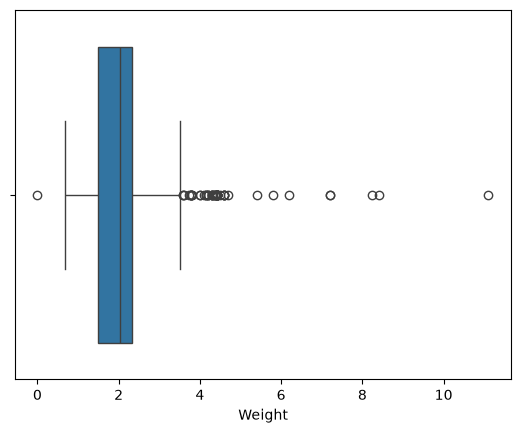

,Company,TypeName,Inches,Weight,Price
128,Acer,Notebook,15.6,7.2000,30476.16
167,Toshiba,Notebook,15.6,5.4000,26053.92
231,Lenovo,Notebook,15.6,7.2000,31381.92
292,Lenovo,Notebook,17.3,5.8000,34578.72
316,Acer,Notebook,15.6,8.2300,29250.72
338,Dell,Ultrabook,15.6,0.0002,35324.64
572,Lenovo,Ultrabook,14.0,8.4000,89137.44
612,Asus,Ultrabook,14.0,11.1000,101232.00
638,Dell,Notebook,15.6,6.2000,48964.32


In [14]:
sns.boxplot(x=df["Weight"])
plt.show()
df[(df["Weight"] < 0.5) | (df["Weight"] > 5)][["Company", "TypeName", "Inches", "Weight", "Price"]]

The box plot shows that most laptops weigh between about 1.5 and 2.3 kg, and the median is about 2 kg. The dot at 0 is a Dell that weighs 0.0002 kg, which is impossible. The dots between 3.6 and 4.7 kg are heavy gaming laptops with 17-inch screens, which are real. The dots from 5.4 to 11.1 kg are not realistic for laptops like a 14-inch ultrabook, so they are typing errors. Unlike the high prices, these values are wrong, not just extreme.

In [15]:
df = df[(df["Weight"] >= 0.5) & (df["Weight"] <= 5)].reset_index(drop=True)
df.shape

(1232, 11)

I removed the 9 rows with weight below 0.5 kg or above 5 kg. Gaming laptops at 4 to 4.7 kg are real, so they stay. Now there are 1,232 rows.

**FEATURE ENGINEERING**


The columns ScreenResolution, Cpu, Memory and Gpu have several facts packed in one text, so I split them into simple columns.

**Screen:** touchscreen, IPS and PPI (pixels per inch, a higher number means a sharper screen).


In [16]:
df["Touchscreen"] = df["ScreenResolution"].str.contains("Touchscreen").astype(int)
df["IPS"] = df["ScreenResolution"].str.contains("IPS").astype(int)

res = df["ScreenResolution"].str.extract(r"(\d+)x(\d+)").astype(int)
df["PPI"] = (((res[0] ** 2 + res[1] ** 2) ** 0.5) / df["Inches"]).round(2)

df[["ScreenResolution", "Touchscreen", "IPS", "PPI"]].head()

,ScreenResolution,Touchscreen,IPS,PPI
0,IPS Panel Retina Display 2560x1600,0,1,226.98
1,1440x900,0,0,127.68
2,Full HD 1920x1080,0,0,141.21
3,IPS Panel Retina Display 2880x1800,0,1,220.53
4,IPS Panel Retina Display 2560x1600,0,1,226.98


processor features

In [17]:
def cpu_brand(text):
    if text.startswith("Intel Core"):
        return " ".join(text.split()[:3])
    elif text.startswith("Intel"):
        return "Other Intel"
    elif text.startswith("AMD"):
        return "AMD"
    return "Other"

df["Cpu_brand"] = df["Cpu"].apply(cpu_brand)
df["Cpu_GHz"] = df["Cpu"].str.extract(r"(\d+\.?\d*)GHz").astype(float)

df["Cpu_brand"].value_counts()

Cpu_brand
Intel Core i7    497
Intel Core i5    407
Intel Core i3    129
Other Intel      121
AMD               60
Intel Core M      17
Other              1
Name: count, dtype: int64

**Storage:** SSD and HDD size in GB (SSD is faster and costs more), with TB changed to GB.


In [18]:
def storage_gb(memory):
    ssd = hdd = 0.0
    for part in memory.split("+"):
        part = part.strip()
        size, unit = re.match(r"(\d+\.?\d*)\s*(GB|TB)", part).groups()
        gb = float(size) * (1000 if unit == "TB" else 1)
        if "SSD" in part:
            ssd += gb
        elif "HDD" in part:
            hdd += gb
    return pd.Series([ssd, hdd])

df[["SSD", "HDD"]] = df["Memory"].apply(storage_gb)
df[["Memory", "SSD", "HDD"]].head()

,Memory,SSD,HDD
0,128GB SSD,128.0,0.0
1,128GB Flash Storage,0.0,0.0
2,256GB SSD,256.0,0.0
3,512GB SSD,512.0,0.0
4,256GB SSD,256.0,0.0


**Graphics card brand and operating system.** I removed the one laptop with an ARM graphics chip because one example is too few to learn from.

In [19]:
df["Gpu_brand"] = df["Gpu"].str.split().str[0]
df = df[df["Gpu_brand"] != "ARM"]

def os_group(name):
    if name in ["Windows 10", "Windows 7", "Windows 10 S"]:
        return "Windows"
    elif name in ["macOS", "Mac OS X"]:
        return "Mac"
    elif name == "Linux":
        return "Linux"
    return "Other/No OS"

df["OS"] = df["OpSys"].apply(os_group)

print(df["Gpu_brand"].value_counts())
print(df["OS"].value_counts())

Gpu_brand
Intel     678
Nvidia    386
AMD       167
Name: count, dtype: int64
OS
Windows        1063
Other/No OS      90
Linux            57
Mac              21
Name: count, dtype: int64


In [20]:
df = df.drop(columns=["ScreenResolution", "Inches", "Cpu", "Memory", "Gpu", "OpSys"]).reset_index(drop=True)
print(df.shape)
df.isnull().sum().sum()

(1231, 14)


np.int64(0)

**ENCODING**

In [21]:
X = pd.get_dummies(df.drop(columns="Price"),
                   columns=["Company", "TypeName", "Cpu_brand", "Gpu_brand", "OS"],
                   drop_first=True).astype(float)
y = df["Price"]

print(X.shape)
X.head()

(1231, 41)


,Ram,Weight,Touchscreen,IPS,PPI,Cpu_GHz,SSD,HDD,Company_Apple,Company_Asus,...,Cpu_brand_Intel Core M,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel,Gpu_brand_Intel,Gpu_brand_Nvidia,OS_Mac,OS_Other/No OS,OS_Windows
0,8.0,1.37,0.0,1.0,226.98,2.3,128.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,8.0,1.34,0.0,0.0,127.68,1.8,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,8.0,1.86,0.0,0.0,141.21,2.5,256.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,16.0,1.83,0.0,1.0,220.53,2.7,512.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,8.0,1.37,0.0,1.0,226.98,3.1,256.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


The model can only work with numbers, so I used one-hot encoding for the text columns (brand, type, processor, graphics card and OS). I did not use 1, 2, 3 for the brands because that would give them a fake order. After this there are 41 input columns.

**PHASE 3: MODEL TRAINING**

Train and test split (80% / 20%)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(984, 41) (247, 41)


FEATURE SCALING


In [23]:
num_cols = ["Ram", "Weight", "PPI", "Cpu_GHz", "SSD", "HDD"]

scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

X_train_s[num_cols].head()

,Ram,Weight,PPI,Cpu_GHz,SSD,HDD
1069,1.275137,0.765721,-0.113675,0.576878,-0.312093,1.113178
898,-0.789704,-0.865821,0.266334,-0.019015,-0.312093,-0.804012
425,-0.789704,0.197595,-0.113675,-2.402589,-0.312093,-0.804012
1227,-0.789704,-0.385099,0.266334,0.378247,-0.312093,-0.804012
811,-0.789704,0.168460,-0.113675,0.775509,0.370114,-0.804012


I split the data 80/20 so I can test on laptops the model has never seen. I scaled only the six numeric columns, learning the scaling from the training set alone to avoid data leakage.

## Training the 5 models
Each model learns from the 984 training laptops (`fit`), then guesses the prices of the 247 test laptops (`predict`), and I compare the guesses with the real prices.

In [24]:
models = {
    "Linear Regression": LinearRegression(),
    "SVR": SVR(kernel="rbf", C=100000),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    mse = mean_squared_error(y_test, pred)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(results).round(3).sort_values("R2", ascending=False)
results

,Model,MAE,MSE,RMSE,R2
2,KNN,11294.121,2.858671e+08,16907.604,0.800
4,Random Forest,10426.993,2.964369e+08,17217.342,0.793
1,SVR,10710.796,3.116562e+08,17653.788,0.782
0,Linear Regression,13127.142,4.121761e+08,20302.121,0.712
3,Decision Tree,12917.815,4.141744e+08,20351.275,0.711


I trained five models and compared them on the 20% of laptops they had not seen. KNN and Random Forest scored best (R2 about 0.79 to 0.80), and Linear Regression and Decision Tree scored lowest (about 0.71). The best models explain about 79% of the price differences, with a typical error of about 10,000 to 11,000 rupees.

## Phase 4: Model Evaluation

- **MAE:** the average size of the mistake, in rupees.
- **MSE:** the average of the squared mistakes. It is a huge number, so I use RMSE instead.
- **RMSE:** MSE brought back to rupees. It is bigger than MAE when a few guesses are very wrong.
- **R2:** the share of the price differences the model explains. 1 is perfect and 0 is no better than always guessing the average price.

Lower MAE, MSE and RMSE are better. A higher R2 is better.

### Overfitting check: train score vs test score

In [25]:
for name, model in models.items():
    train_r2 = r2_score(y_train, model.predict(X_train_s))
    test_r2 = r2_score(y_test, model.predict(X_test_s))
    print(f"{name:20s} train R2 = {train_r2:.3f}   test R2 = {test_r2:.3f}")

Linear Regression    train R2 = 0.776   test R2 = 0.712
SVR                  train R2 = 0.921   test R2 = 0.782
KNN                  train R2 = 0.827   test R2 = 0.800
Decision Tree        train R2 = 0.997   test R2 = 0.711
Random Forest        train R2 = 0.972   test R2 = 0.793


KNN has the best test score (0.800) and its training score is 0.827, so the gap is small. It is the most consistent model.

Random Forest is nearly as good (0.793) and has the lowest typical error in rupees among the top three (MAE 10,427).

The Decision Tree overfit. It scores 0.997 on the training laptops but only 0.711 on new ones, so it memorised the training data.

Linear Regression is the lowest (0.712), maybe because laptop prices do not follow a simple straight line from the specs.

### Which features matter most


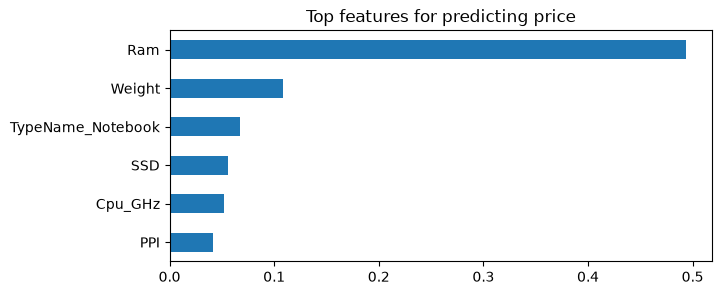

In [26]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

importance.head(6).plot(kind="barh", figsize=(7, 3))
plt.gca().invert_yaxis()
plt.title("Top features for predicting price")
plt.show()

RAM is by far the strongest price signal. Weight comes next, probably because heavy laptops tend to be gaming machines and workstations. Storage (SSD size) and processor speed also matter.

## Conclusion

- I cleaned the data (removed empty rows, duplicates and 9 laptops with impossible weights), made new features like PPI, SSD size and HDD size, and trained five models.
- KNN had the best test score (R2 = 0.80) and Random Forest was very close (R2 = 0.79). This means the models explain about 80% of the changes in price. The average error of Random Forest is about 10,400 rupees.
- I used Random Forest for the web app. Its score is almost the same as KNN, its average error is a bit lower (10,427 compared to 11,294), and it can show which features matter most.
- The Decision Tree overfit. It got 0.997 on the training data but only 0.711 on the test data. Linear Regression was the lowest (0.71), maybe because the price does not go up in a straight line with the specs.
- RAM was the most important feature for the price. Weight and SSD size also mattered.
- Limits: the dataset is small (about 1,200 laptops), I used only one train/test split, and I did not tune the models. Expensive laptops are rare, so the errors in rupees are bigger for them.

 #### saving the model for the web app

Now that testing is done, I trained the Random Forest again on all the data and saved it with joblib. The web app loads this file, so the model does not have to be trained again every time.

In [27]:
final_model = RandomForestRegressor(n_estimators=100, random_state=42)
final_model.fit(X, y)

categorical = ["Company", "TypeName", "Cpu_brand", "Gpu_brand", "OS"]
options = {col: sorted(df[col].unique().tolist()) for col in categorical}

joblib.dump({"model": final_model, "columns": X.columns.tolist(), "options": options},
            "laptop_model.joblib", compress=3)

import sklearn
print(f"scikit-learn=={sklearn.__version__}")
print(f"pandas=={pd.__version__}")
print(f"joblib=={joblib.__version__}")
print("streamlit")

scikit-learn==1.9.1
pandas==3.1.0
joblib==1.6.0
streamlit
